<a href="https://colab.research.google.com/github/dbswp3730/apple-price/blob/main/%EC%82%AC%EA%B3%BC%EA%B0%80%EA%B2%A9%EC%98%88%EC%B8%A1_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 명절·품종 정보를 반영한 사과 도매가격 예측 (Keras, Google Colab)
- 데이터: 사과 20kg 상자 · 특 등급 경락 데이터 (2022-01-04 ~ 2026-11-17, **1,467거래일 전체 사용 — 거래가 적은 68일 포함**)
- 입력: 지난 30거래일의 가격, 거래물량, 요일, 명절 D-day, 품종 구성 비율
- 출력: **다음 거래일 가격 (천원/kg)**
- 손실 함수: `mean_squared_logarithmic_error` (MSLE)
- 비교: Naive(전일가), 5일 이동평균, MLP, SimpleRNN, LSTM, GRU

런타임 → 모두 실행. 데이터는 GitHub에서 바로 읽습니다. GPU가 필요하지 않습니다(CPU로 약 5~10분).

## 0. 한글 폰트 설정

In [1]:
!apt-get -qq install -y fonts-nanum > /dev/null
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
fm.fontManager.addfont('/usr/share/fonts/truetype/nanum/NanumGothic.ttf')
plt.rc('font', family='NanumGothic')
plt.rc('axes', unicode_minus=False)

## 1. 데이터 불러오기 (GitHub 저장소)

In [2]:
from google.colab import files   # 마지막 셀(엑셀 내려받기)에서 사용

# GitHub 저장소의 '서울 사과 데이터.xlsx'를 주소로 바로 읽기
FILE = 'https://raw.githubusercontent.com/dbswp3730/apple-price/main/%EC%84%9C%EC%9A%B8%20%EC%82%AC%EA%B3%BC%20%EB%8D%B0%EC%9D%B4%ED%84%B0.xlsx'
print(FILE)

https://raw.githubusercontent.com/dbswp3730/apple-price/main/%EC%84%9C%EC%9A%B8%20%EC%82%AC%EA%B3%BC%20%EB%8D%B0%EC%9D%B4%ED%84%B0.xlsx


## 2. 일별 데이터 만들기 (68일 포함)

In [3]:
import numpy as np
import pandas as pd

raw = pd.read_excel(FILE)
raw['DATE'] = pd.to_datetime(raw['DATE'])
raw['평균가격'] = pd.to_numeric(raw['평균가격'], errors='coerce')
raw = raw.dropna(subset=['평균가격'])

# 품종 -> 품종군 (나머지는 '기타')
VARIETY_GROUP = {
    '미얀마': '후지계열', '후지': '후지계열', '후지후브락스': '후지계열', '미야비': '후지계열',
    '미시마': '후지계열', '로얄부사': '후지계열', '착색후지': '후지계열', '하나후지': '후지계열', '로얄후지': '후지계열',
    '홍로': '홍로',
    '아오리': '조생종', '썸머킹': '조생종', '썸머프린스': '조생종', '하쯔쓰가루': '조생종',
    '시나노골드': '시나노골드', '감홍': '감홍', '아리수': '아리수',
}
GROUPS = ['후지계열', '홍로', '조생종', '시나노골드', '감홍', '아리수', '기타']
raw['그룹'] = raw['품종'].map(VARIETY_GROUP).fillna('기타')

# 일별 집계: 가격 = 총거래금액 합 / 총거래물량(kg) 합  (원/kg, 거래량 가중평균)
g = raw.groupby('DATE')
daily = pd.DataFrame({'amount': g['총거래금액'].sum(), 'kg': g['총거래물량'].sum(), 'lots': g.size()})
daily['price'] = daily['amount'] / daily['kg']

# 품종 구성 비율 (당일 거래물량 중 비중)
share = raw.pivot_table(index='DATE', columns='그룹', values='총거래물량', aggfunc='sum', fill_value=0)
share = share.reindex(columns=GROUPS, fill_value=0)
share = share.div(share.sum(axis=1), axis=0)
share.columns = ['share_' + c for c in GROUPS]
daily = daily.join(share)

# 거래가 적은 날 표시 (제거하지 않고 그래프에만 표시)
daily['thin'] = (daily['kg'] < 2000) | (daily['lots'] < 3)
print('전체 거래일:', len(daily), '/ 거래가 적은 날:', daily['thin'].sum())
daily.head()

전체 거래일: 1467 / 거래가 적은 날: 68


,amount,kg,lots,price,share_후지계열,share_홍로,share_조생종,share_시나노골드,share_감홍,share_아리수,share_기타,thin
DATE,,,,,,,,,,,,
2022-01-04,335608000,105660,36,3176.301344,0.960250,0.0,0.0,0.0,0.0,0.0,0.039750,False
2022-01-05,267562500,82020,33,3262.161668,0.931968,0.0,0.0,0.0,0.0,0.0,0.068032,False
2022-01-06,598326300,214220,40,2793.045934,0.421623,0.0,0.0,0.0,0.0,0.0,0.578377,False
2022-01-07,279881700,92880,39,3013.368863,0.941430,0.0,0.0,0.0,0.0,0.0,0.058570,False
2022-01-08,183282600,57460,35,3189.742430,0.904281,0.0,0.0,0.0,0.0,0.0,0.095719,False


Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


## 3. 데이터 그래프 (68일 표시)

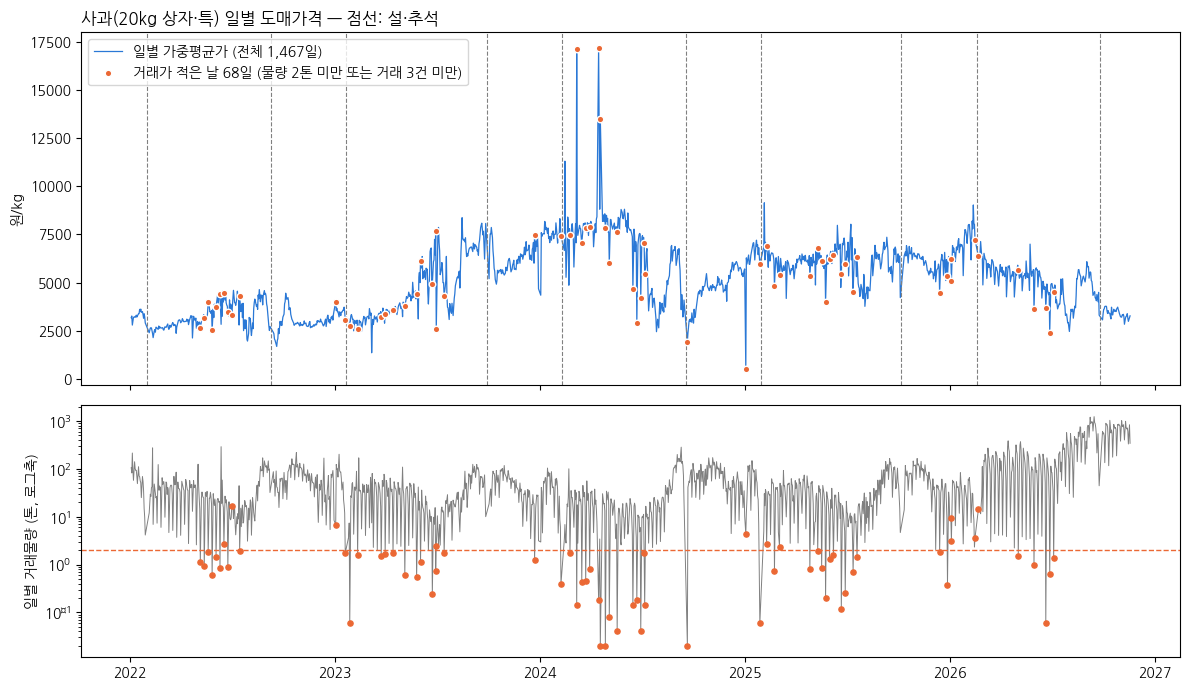

In [4]:
HOLIDAYS = pd.to_datetime(['2022-02-01', '2022-09-10', '2023-01-22', '2023-09-29', '2024-02-10',
                           '2024-09-17', '2025-01-29', '2025-10-06', '2026-02-17', '2026-09-25', '2027-02-07'])
thin = daily[daily['thin']]

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True, gridspec_kw={'height_ratios': [1.4, 1]})
axes[0].plot(daily.index, daily['price'], color='#2a78d6', lw=0.9, label=f'일별 가중평균가 (전체 {len(daily):,}일)')
axes[0].scatter(thin.index, thin['price'], s=22, color='#eb6834', edgecolor='white', zorder=3,
                label=f'거래가 적은 날 {len(thin)}일 (물량 2톤 미만 또는 거래 3건 미만)')
for h in HOLIDAYS[HOLIDAYS <= daily.index.max()]:
    axes[0].axvline(h, color='gray', lw=0.8, ls='--')
axes[0].set_ylabel('원/kg'); axes[0].legend(loc='upper left')
axes[0].set_title('사과(20kg 상자·특) 일별 도매가격 — 점선: 설·추석', loc='left')
axes[1].plot(daily.index, daily['kg'] / 1000, color='gray', lw=0.7)
axes[1].scatter(thin.index, thin['kg'] / 1000, s=14, color='#eb6834', zorder=3)
axes[1].axhline(2, color='#eb6834', ls='--', lw=1)
axes[1].set_yscale('log'); axes[1].set_ylabel('일별 거래물량 (톤, 로그축)')
plt.tight_layout(); plt.show()

## 4. 입력 변수 만들기
| 변수 | 내용 |
|---|---|
| log_price, log_ret | 로그 가격, 전일 대비 로그 변화율 (학습 구간 평균·표준편차로 표준화) |
| log_kg | 로그 거래물량 (표준화) |
| dow_월 ~ dow_토 | 요일 원-핫 (일요일 거래 없음) |
| dday | 다음 설·추석까지 남은 달력일수 / 60 (60일 이상은 1) |
| share_* | 품종군 7개의 물량 비중 |

In [5]:
df = daily.copy()
df['log_price'] = np.log(df['price'])
df['log_ret'] = df['log_price'].diff().fillna(0.0)
df['log_kg'] = np.log(df['kg'])

# 명절 D-day: 다음 명절까지 남은 일수 (0~60) -> 0~1
nxt = HOLIDAYS[HOLIDAYS.searchsorted(df.index, side='left')]
df['dday'] = np.clip((nxt - df.index).days, 0, 60) / 60

DOW = ['월', '화', '수', '목', '금', '토']
for k, d in enumerate(DOW):
    df['dow_' + d] = (df.index.dayofweek == k).astype(float)

SEQ_COLS = ['log_price', 'log_ret', 'log_kg'] + ['dow_' + d for d in DOW] + ['dday'] + ['share_' + c for c in GROUPS]
FUT_COLS = ['dow_' + d for d in DOW] + ['dday']     # 예측하는 날의 요일·D-day (미리 알 수 있는 값)
print('시퀀스 입력 변수', len(SEQ_COLS), '개 / 예측일 달력 변수', len(FUT_COLS), '개')

시퀀스 입력 변수 17 개 / 예측일 달력 변수 7 개


## 5. 시퀀스 구성과 학습/검증/테스트 분할
- 입력: t-29 ~ t일 (30거래일), 타깃: t+1일 가격 (천원/kg)
- 시간 순서대로 분할 (예측 대상일 기준): 학습 ~2025-06 / 검증 2025-07~12 / 테스트 2026-01~11
- 표준화 통계는 학습 구간에서만 계산 → 테스트 정보가 학습에 새지 않도록

In [6]:
WINDOW, HORIZON = 30, 1
TRAIN_END, VAL_END = pd.Timestamp('2025-07-01'), pd.Timestamp('2026-01-01')

feat = df.copy()
train_rows = feat.index < TRAIN_END
for c in ['log_price', 'log_ret', 'log_kg']:
    mu, sd = feat.loc[train_rows, c].mean(), feat.loc[train_rows, c].std()
    feat[c] = (feat[c] - mu) / sd

S = feat[SEQ_COLS].values.astype('float32')
Fu = feat[FUT_COLS].values.astype('float32')
P = df['price'].values
dates = df.index

X_seq, X_fut, y, p_today, p_ma5, tgt_date = [], [], [], [], [], []
for t in range(WINDOW - 1, len(df) - HORIZON):
    X_seq.append(S[t - WINDOW + 1:t + 1])
    X_fut.append(Fu[t + HORIZON])
    y.append(P[t + HORIZON] / 1000)          # 천원/kg
    p_today.append(P[t]); p_ma5.append(P[t - 4:t + 1].mean())
    tgt_date.append(dates[t + HORIZON])
X_seq, X_fut = np.array(X_seq), np.array(X_fut)
y, p_today, p_ma5 = np.array(y, dtype='float32'), np.array(p_today), np.array(p_ma5)
tgt_date = pd.DatetimeIndex(tgt_date)

tr = tgt_date < TRAIN_END
va = (tgt_date >= TRAIN_END) & (tgt_date < VAL_END)
te = tgt_date >= VAL_END
Xs_tr, Xf_tr, y_tr = X_seq[tr], X_fut[tr], y[tr]
Xs_va, Xf_va, y_va = X_seq[va], X_fut[va], y[va]
Xs_te, Xf_te, y_te = X_seq[te], X_fut[te], y[te]
print('학습', Xs_tr.shape, '검증', Xs_va.shape, '테스트', Xs_te.shape)

학습 (1020, 30, 17) 검증 (152, 30, 17) 테스트 (265, 30, 17)


## 6. 평가 지표와 기준 모델

In [7]:
def evaluate(pred_won, true_won):
    e = pred_won - true_won
    return {'MAE': np.abs(e).mean(), 'RMSE': np.sqrt((e ** 2).mean()), 'MAPE(%)': 100 * np.abs(e / true_won).mean()}

true_te = y_te * 1000                        # 원/kg
results = {
    'Naive(전일가)': evaluate(p_today[te], true_te),
    '5일 이동평균': evaluate(p_ma5[te], true_te),
}
pd.DataFrame(results).T.round(1)

,MAE,RMSE,MAPE(%)
Naive(전일가),377.3,590.6,7.7
5일 이동평균,391.4,553.4,8.2


## 7. 모델 정의와 컴파일
- 순환 모델: 30일 시퀀스 → SimpleRNN/LSTM/GRU(32) → Dropout(0.2) → [마지막 은닉상태 + 예측일 요일·D-day] → Dense(16, ReLU) → Dense(1)
- MLP: 시퀀스를 펼침(30×17) + 예측일 요일·D-day → Dense(128, ReLU) → Dropout(0.2) → Dense(16, ReLU) → Dense(1)
- 출력층 bias를 학습 타깃 평균으로 초기화: MSLE는 예측값이 0 이하이면 0 근처로 잘라서 계산하므로, 처음부터 양수 근처에서 출발시킴
- optimizer: AdamW (weight decay 1e-4), 전체 기울기 norm 5로 clipping

In [8]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

N_SEQ, N_FUT = Xs_tr.shape[2], Xf_tr.shape[1]
CONFIG = {                 # (은닉 크기, learning rate) — 검증 RMSE로 고른 값
    'MLP': (64, 1e-3), 'SimpleRNN': (32, 1e-3), 'LSTM': (32, 3e-4), 'GRU': (32, 3e-4),
}

def build_model(name):
    hidden, lr = CONFIG[name]
    seq_in = keras.Input(shape=(WINDOW, N_SEQ), name='seq')     # 지난 30일 변수
    fut_in = keras.Input(shape=(N_FUT,), name='future')         # 예측일 요일·D-day
    if name == 'MLP':
        z = layers.Concatenate()([layers.Flatten()(seq_in), fut_in])
        z = layers.Dense(hidden * 2, activation='relu')(z)
        z = layers.Dropout(0.2)(z)
    else:
        rnn = {'SimpleRNN': layers.SimpleRNN, 'LSTM': layers.LSTM, 'GRU': layers.GRU}[name]
        h = rnn(hidden)(seq_in)                                 # 마지막 시점 은닉상태
        h = layers.Dropout(0.2)(h)
        z = layers.Concatenate()([h, fut_in])
    z = layers.Dense(16, activation='relu')(z)
    out = layers.Dense(1, bias_initializer=keras.initializers.Constant(float(y_tr.mean())))(z)
    model = keras.Model([seq_in, fut_in], out, name=name)

    model.compile(optimizer=keras.optimizers.AdamW(learning_rate=lr, weight_decay=1e-4, global_clipnorm=5.0),
                  loss='mean_squared_logarithmic_error',
                  metrics=['mae'])
    return model

build_model('GRU').summary()

Model: "GRU"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ seq (InputLayer)    │ (None, 30, 17)    │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gru (GRU)           │ (None, 32)        │      4,896 │ seq[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 32)        │          0 │ gru[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ future (InputLayer) │ (None, 7)         │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 39)        │          0 │ dropout[0][0],    │
│ (Concatenate)       │                   │            │ future[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 16)        │        640 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 1)         │         17 │ dense[0][0]       │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 5,553 (21.69 KB)

 Trainable params: 5,553 (21.69 KB)

 Non-trainable params: 0 (0.00 B)

## 8. 모델 실행 (model.fit)
- `epochs=300`: 최대 300번 반복. 검증 손실이 25 epoch 동안 좋아지지 않으면 EarlyStopping이 멈추고 가장 좋았던 가중치로 되돌림
- `batch_size=32`: 학습 샘플 1,020개를 32개씩 나눠 넣음 → 1 epoch당 가중치 업데이트 32번
- 시드 3개로 반복해 평균과 표준편차를 봄 (같은 모델도 초기값에 따라 결과가 달라짐)

In [9]:
SEEDS = [0, 1, 2]
histories, preds = {}, {}

for name in ['MLP', 'SimpleRNN', 'LSTM', 'GRU']:
    histories[name], preds[name] = [], []
    for seed in SEEDS:
        keras.utils.set_random_seed(seed)
        model = build_model(name)
        early_stop = keras.callbacks.EarlyStopping(monitor='val_loss', patience=25, restore_best_weights=True)

        history = model.fit([Xs_tr, Xf_tr], y_tr,
                            epochs=300, batch_size=32,
                            validation_data=([Xs_va, Xf_va], y_va),
                            callbacks=[early_stop], verbose=0)

        pred = model.predict([Xs_te, Xf_te], verbose=0).ravel() * 1000      # 원/kg
        histories[name].append(history.history); preds[name].append(pred)
        best_ep = int(np.argmin(history.history['val_loss'])) + 1
        print(f"{name:9s} seed {seed}  best epoch {best_ep:3d}  " +
              '  '.join(f'{k} {v:.1f}' for k, v in evaluate(pred, true_te).items()))

MLP       seed 0  best epoch   3  MAE 523.2  RMSE 673.6  MAPE(%) 11.3
MLP       seed 1  best epoch   4  MAE 512.2  RMSE 672.0  MAPE(%) 10.5
MLP       seed 2  best epoch   3  MAE 481.3  RMSE 646.6  MAPE(%) 10.0
SimpleRNN seed 0  best epoch  18  MAE 417.9  RMSE 544.3  MAPE(%) 9.2
SimpleRNN seed 1  best epoch  16  MAE 369.6  RMSE 504.7  MAPE(%) 7.8
SimpleRNN seed 2  best epoch  22  MAE 415.1  RMSE 533.6  MAPE(%) 8.9
LSTM      seed 0  best epoch  28  MAE 391.2  RMSE 547.7  MAPE(%) 8.0
LSTM      seed 1  best epoch  44  MAE 403.7  RMSE 544.7  MAPE(%) 8.7
LSTM      seed 2  best epoch  39  MAE 387.8  RMSE 531.7  MAPE(%) 8.0
GRU       seed 0  best epoch  61  MAE 370.5  RMSE 501.2  MAPE(%) 8.1
GRU       seed 1  best epoch  42  MAE 325.2  RMSE 458.1  MAPE(%) 6.8
GRU       seed 2  best epoch  59  MAE 330.1  RMSE 456.6  MAPE(%) 6.9


## 9. 결과표 (테스트 2026-01 ~ 11, 원/kg)

In [10]:
rows = []
for k, v in results.items():
    rows.append({'모델': k, **{m: f'{x:.1f}' for m, x in v.items()}})
for name in preds:
    ms = pd.DataFrame([evaluate(p, true_te) for p in preds[name]])
    rows.append({'모델': name, **{m: f'{ms[m].mean():.1f} ± {ms[m].std(ddof=0):.1f}' for m in ms}})
table = pd.DataFrame(rows).set_index('모델')
table

,MAE,RMSE,MAPE(%)
모델,,,
Naive(전일가),377.3,590.6,7.7
5일 이동평균,391.4,553.4,8.2
MLP,505.6 ± 17.8,664.1 ± 12.3,10.6 ± 0.5
SimpleRNN,400.9 ± 22.2,527.5 ± 16.7,8.6 ± 0.6
LSTM,394.2 ± 6.8,541.4 ± 6.9,8.2 ± 0.3
GRU,341.9 ± 20.3,472.0 ± 20.7,7.3 ± 0.6


## 10. 학습 곡선 (loss = MSLE)

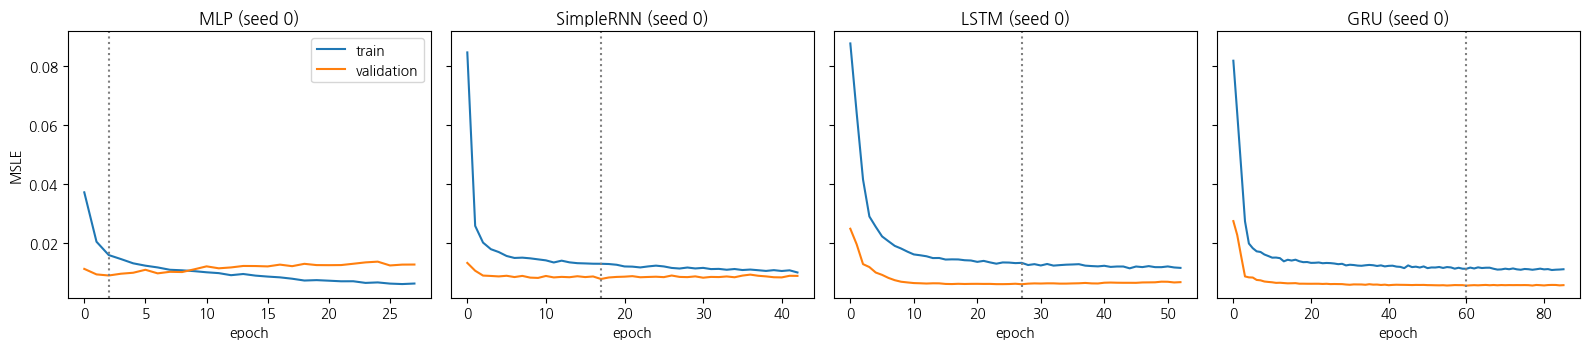

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6), sharey=True)
for ax, name in zip(axes, histories):
    h = histories[name][0]
    ax.plot(h['loss'], label='train')
    ax.plot(h['val_loss'], label='validation')
    ax.axvline(int(np.argmin(h['val_loss'])), color='gray', ls=':')
    ax.set_title(f'{name} (seed 0)'); ax.set_xlabel('epoch')
axes[0].set_ylabel('MSLE'); axes[0].legend()
plt.tight_layout(); plt.show()

## 11. 예측값 vs 실제값 (테스트 구간, 68일 중 테스트에 들어간 날 표시)

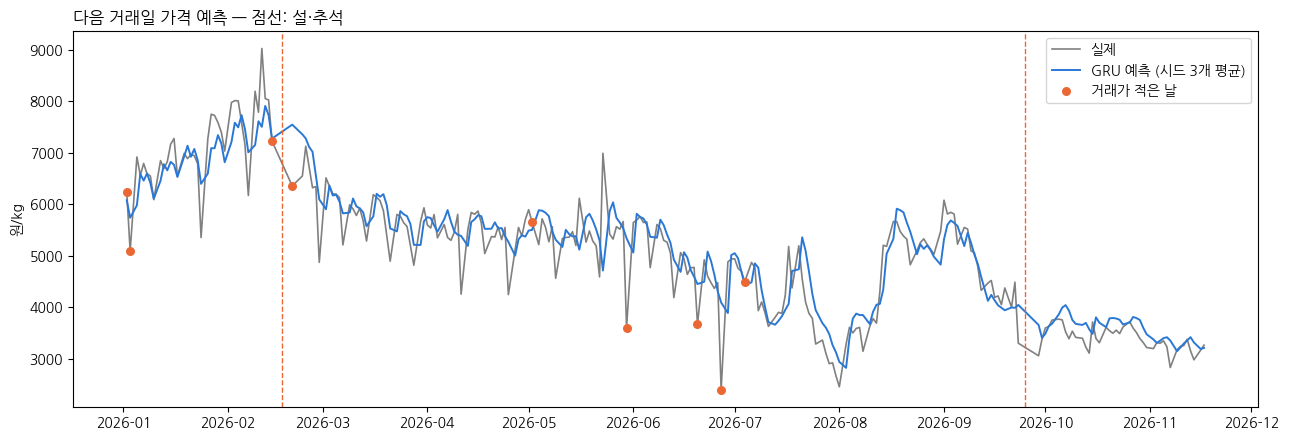

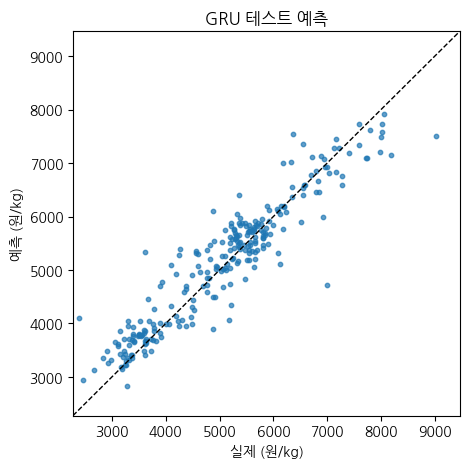

In [12]:
best = min(preds, key=lambda n: np.mean([evaluate(p, true_te)['RMSE'] for p in preds[n]]))
ens = np.mean(preds[best], axis=0)
d_te = tgt_date[te]
thin_te = df.loc[d_te, 'thin'].values

fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(d_te, true_te, color='gray', lw=1.2, label='실제')
ax.plot(d_te, ens, color='#2a78d6', lw=1.4, label=f'{best} 예측 (시드 {len(SEEDS)}개 평균)')
ax.scatter(d_te[thin_te], true_te[thin_te], s=30, color='#eb6834', zorder=3, label='거래가 적은 날')
for h in HOLIDAYS[(HOLIDAYS > d_te.min()) & (HOLIDAYS < d_te.max())]:
    ax.axvline(h, color='#eb6834', lw=1, ls='--')
ax.set_ylabel('원/kg'); ax.legend(); ax.set_title('다음 거래일 가격 예측 — 점선: 설·추석', loc='left')
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(true_te, ens, s=10, alpha=0.7)
lim = [min(true_te.min(), ens.min()) * 0.95, max(true_te.max(), ens.max()) * 1.05]
ax.plot(lim, lim, 'k--', lw=1); ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel('실제 (원/kg)'); ax.set_ylabel('예측 (원/kg)'); ax.set_title(f'{best} 테스트 예측')
plt.show()

## 12. (선택) 예측 결과 엑셀로 내려받기

In [13]:
out = pd.DataFrame({'예측대상일': d_te.date, '실제(원/kg)': true_te.round(1), '거래적은날': thin_te,
                    'Naive(전일가)': p_today[te].round(1), '5일 이동평균': p_ma5[te].round(1)})
for name in preds:
    out[name] = np.mean(preds[name], axis=0).round(1)
with pd.ExcelWriter('사과가격_예측결과.xlsx') as w:
    table.to_excel(w, sheet_name='모델비교')
    out.to_excel(w, sheet_name='테스트예측', index=False)
files.download('사과가격_예측결과.xlsx')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>